# AirGuard India — Phase 2: Preprocessing and Exploratory Data Analysis

**AD23532 · Principles of Data Science**
Rajalakshmi Engineering College (Autonomous, affiliated to Anna University, Chennai)

| | |
| --- | --- |
| Phase | 2 of 3 — Review 2 |
| Rubric rows addressed | Data quality; preprocessing and cleansing; transformation and feature engineering; EDA; interpretation |
| Degree and branch | B.Tech. Artificial Intelligence and Data Science |
| Regulation / Year / Semester | 2023 / 2026-27 (ODD) / V |
| Team | 260586 (Nishanth Rajendran), 260598 (<NAME>), 260600 (<NAME>) |
| Repository | https://github.com/nishaids/airguard-india |

---

> **How to read this notebook.** It contains orchestration and narrative only.
> Every piece of analysis logic lives in the `src/` package and is imported
> here, so nothing shown below can drift away from the code that produced the
> committed results. Every number displayed is read from `results/*.json`, which
> the pipeline writes; none is typed by hand.


In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config

config.set_global_seed()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RESULTS = config.RESULTS_DIR
FIGURES = config.FIGURES_DIR

def load(name: str) -> dict:
    """Load a results artefact by file name."""
    path = RESULTS / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}

def show(filename: str, caption: str = "") -> None:
    """Display a pipeline-generated figure with its caption."""
    path = FIGURES / filename
    if path.exists():
        display(Image(filename=str(path), width=900))
        if caption:
            display(Markdown(f"*{caption}*"))
    else:
        display(Markdown(f"> Figure `{filename}` not found. Run `python run_all.py`."))

print(f"Project root: {ROOT}")
print(f"Global seed:  {config.RANDOM_SEED}")


Project root: D:\PODS Project\airguard-india
Global seed:  42


## 1. The cleaning decisions, and the evidence for each

Three decisions in this phase could have been made by preference. Each was instead made by measurement, and the measurement is shown.

In [2]:
cleaning = load("cleaning_report.json")
artefacts = cleaning["artefact_policy"]
display(Markdown("### Decision 1 — which extreme values are artefacts?"))
display(Markdown(f"**Retention principle.** {artefacts['retention_principle']}"))
display(pd.DataFrame(artefacts["rule"], index=["Condition"]).T)
display(pd.DataFrame(artefacts["per_pollutant"]).T)
display(Markdown(
    f"**{artefacts['event_window_protected_days']:,} city-days** fall inside a "
    f"documented event window and are exempt from the statistical spike rule. "
    f"In total {artefacts['total_values_set_to_missing']} values were converted "
    f"to missing, and {artefacts['aqi_above_scale_retained_and_flagged']} "
    f"above-scale AQI values were retained and flagged rather than truncated."
))

### Decision 1 — which extreme values are artefacts?

**Retention principle.** Genuine pollution episodes are retained in full. The event-window exemption means that no Diwali, stubble-burning or lockdown observation is ever removed by the statistical spike rule.

,Condition
A,negative concentration
B,above per-pollutant plausible ceiling (config....
C,exactly zero for PM2.5 or PM10
D,isolated spike: |x - median(+/-3d)| > 8.0 scal...


,rule_A_negative,rule_B_above_ceiling,rule_C_impossible_zero,rule_D_isolated_spike,total_set_to_missing
PM2.5,0,0,0,14,14
PM10,0,0,0,2,2
NO,0,0,0,47,47
NO2,0,0,0,7,7
NOx,0,0,0,1,1
NH3,0,0,0,3,3
CO,0,0,0,131,131
SO2,0,0,0,17,17
O3,0,0,0,0,0
Benzene,0,14,0,80,93


**3,633 city-days** fall inside a documented event window and are exempt from the statistical spike rule. In total 371 values were converted to missing, and 93 above-scale AQI values were retained and flagged rather than truncated.

A pollution dataset contains two entirely different kinds of extreme value. An instrument fault must be removed; a Diwali night must not. The rule above separates them on physical grounds — build-up and decay over multiple days against an isolated single-day leap — and it never fires inside a documented event window.

In [3]:
comparison = cleaning["imputation_comparison"]
display(Markdown("### Decision 2 — which imputation strategy?"))
display(Markdown(f"*Method.* {comparison['method']}"))
display(pd.DataFrame([
    {
        "Strategy": r["strategy"],
        "Causal": r["causal"],
        "MAE / IQR": r["mean_mae_over_iqr"],
        "KS statistic": r["mean_ks_statistic"],
        "Mean |std shift| %": r["mean_abs_std_shift_pct"],
    }
    for r in comparison["results"]
]))
display(Markdown(f"**Selection.** {comparison['selection_rationale']}"))

### Decision 2 — which imputation strategy?

*Method.* Masking experiment on the training portion only: 15% of observed cells per column hidden at random with seed 42, then reconstructed. Scored on MAE normalised by the column interquartile range and on distribution shift (KS statistic, Wasserstein distance, moment changes).

,Strategy,Causal,MAE / IQR,KS statistic,Mean |std shift| %
0,global_median,True,0.7571,0.1309,13.105
1,per_city_median,True,0.6249,0.0683,11.093
2,per_city_linear_interpolation,False,0.2547,0.0358,7.460
3,per_city_ffill_limit3,True,0.3223,0.0391,5.214
4,knn_k5,False,0.6922,0.0434,8.604


**Selection.** per_city_linear_interpolation attains the lowest normalised MAE overall (0.2547), but it is non-causal: it reconstructs a gap using observations that follow it. Because the modelling task is to forecast tomorrow from information available today, the adopted strategy is per_city_ffill_limit3, the best of the causal candidates (0.3223 normalised MAE). Adopting a non-causal imputer would inflate reported test performance without improving real forecasting skill.

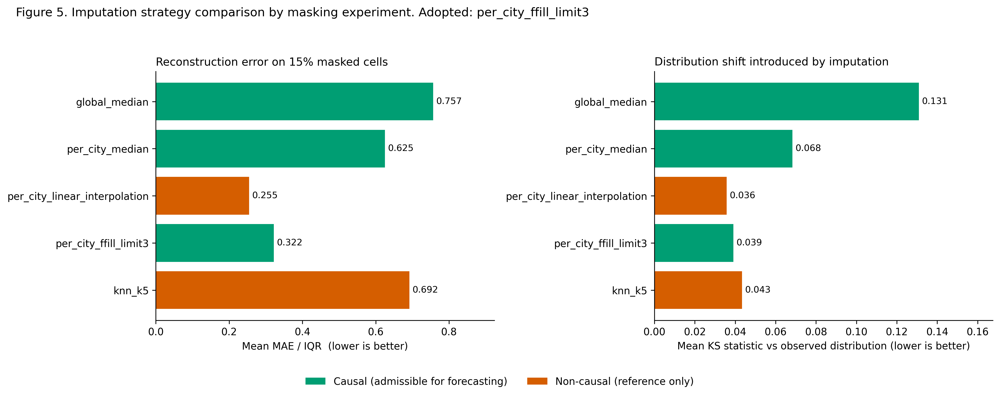

*Figure 1. Reconstruction error and distribution shift for each candidate. Green is causal and admissible for forecasting; orange is reported only to quantify what the causality constraint costs.*

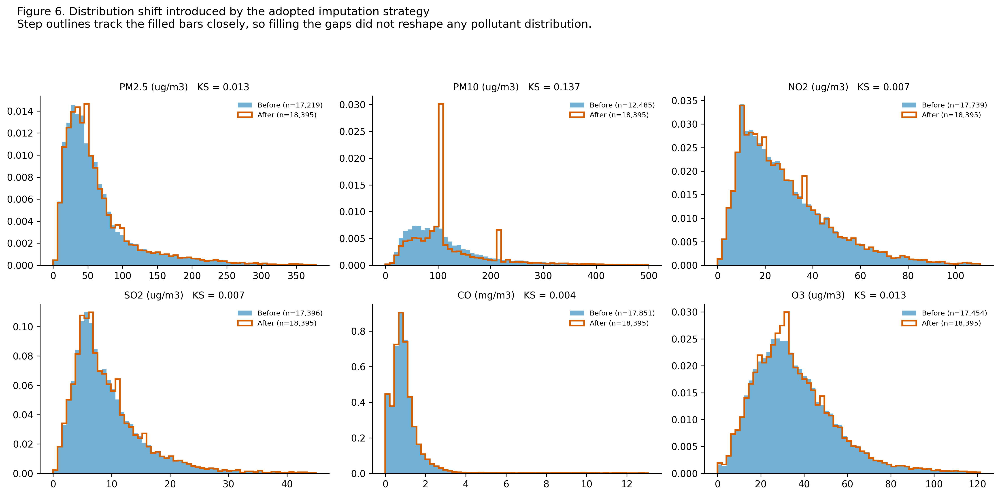

*Figure 2. Distributions before and after the adopted imputation.*

In [4]:
show("05_imputation_strategy_comparison.png",
     "Figure 1. Reconstruction error and distribution shift for each candidate. Green is causal and admissible for forecasting; orange is reported only to quantify what the causality constraint costs.")
show("06_imputation_distribution_shift.png",
     "Figure 2. Distributions before and after the adopted imputation.")

The result is worth stating plainly: linear interpolation reconstructs hidden values best, but it is **not causal** — it fills a gap using the observation that follows it. Since the task is to forecast tomorrow from today, adopting it would inflate reported test performance without improving real forecasting skill. The best causal strategy is adopted instead, and the cost of that constraint is now a measured quantity rather than an unexamined assumption.

In [5]:
validation = cleaning["validation"]
display(Markdown("### Decision 3 — did the cleaning actually work?"))
display(pd.DataFrame([
    {"Assertion": k, "Result": v}
    for k, v in validation.items()
    if isinstance(v, bool)
]))
display(Markdown(
    f"Final shape **{validation['shape']['rows']:,} x {validation['shape']['columns']}** "
    f"across **{validation['cities']}** cities, "
    f"{validation['date_range'][0]} to {validation['date_range'][1]}. "
    f"Split boundary **{validation['split_boundary']}** "
    f"({validation['n_train_rows']:,} train / {validation['n_test_rows']:,} test)."
))

### Decision 3 — did the cleaning actually work?

,Assertion,Result
0,primary_key_unique,True
1,no_nulls_in_pollutants,True
2,no_negative_pollutants,True
3,calendar_complete_per_city,True
4,train_test_date_boundary_respected,True


Final shape **18,395 x 18** across **12** cities, 2015-01-01 to 2020-07-01. Split boundary **2019-05-26** (13,559 train / 4,836 test).

## 2. Feature engineering

Every window ends on the current day and every lag is taken within a city, so no feature can see the future and no city contributes to another city's history.

In [6]:
features = load("feature_engineering_report.json")
display(pd.DataFrame([
    {"Group": k, "Count": v}
    for k, v in features["feature_group_counts"].items()
]))
display(Markdown("### Leakage controls applied"))
for name, text in features["leakage_controls"].items():
    display(Markdown(f"**{name.capitalize()}.** {text}"))

,Group,Count
0,same_day_measurements,16
1,temporal,13
2,event_flags,6
3,lags,32
4,rolling,64
5,ratios,6
6,station_metadata,2
7,hai_and_sub_indices,15
8,encoded_categoricals,24
9,total_candidates,178


### Leakage controls applied

**Temporal.** The split is a fixed calendar boundary; shuffle is never used. TimeSeriesSplit is used for cross-validation. Lags and rolling windows are computed with groupby('City') so no city contributes to another city's history, and no window extends past the current day.

**Target.** AQI_next and AQI_Bucket_next are mutually excluded from each other's feature matrix, and an assertion in build_feature_matrix fails the run if either appears among the candidates. Same-day AQI and AQI_Bucket_ordinal are retained as legitimate predictors because they are known at prediction time; the distinct same-day nowcast leakage is demonstrated empirically in models/train_classification.py.

**Encoder.** The encoding is fitted on the training period only. Applying a full-sample city mean would allow each test row to contribute to the value of its own encoded feature.

**Scaler.** Scaling is performed inside a scikit-learn Pipeline so that fit_transform touches training folds only; no scaler is ever fitted on the test partition.

**Imputation.** All imputation statistics were estimated on pre-boundary rows in src/data/clean.py, and the adopted strategy uses no forward-looking information within a city's series.

## 3. The Health Advisory Index

The index is the project's methodological contribution. Its mathematical properties are asserted in code and re-verified at every pipeline run, so a broken index cannot reach a report.

In [7]:
from src.features import hai as hai_mod

checks = hai_mod.self_test()
display(pd.DataFrame([{"Property": k, "Verified": v} for k, v in checks.items()]))

08:01:42 | INFO    | src.features.hai         | HAI self-test passed: cpcb_breakpoints_reproduced, bounded_0_100, never_less_protective_than_aqi, cohort_ordering_preserved, monotone_in_each_pollutant, vulnerability_factors_valid, advisory_text_complete_all_languages


,Property,Verified
0,cpcb_breakpoints_reproduced,True
1,bounded_0_100,True
2,never_less_protective_than_aqi,True
3,cohort_ordering_preserved,True
4,monotone_in_each_pollutant,True
5,vulnerability_factors_valid,True
6,advisory_text_complete_all_languages,True


In [8]:
display(Markdown("### Cohort vulnerability factors"))
display(pd.DataFrame(hai_mod.VULNERABILITY).T[config.HAI_POLLUTANTS])
display(Markdown(
    "Every factor is at least 1 and the reference cohort is exactly 1 "
    "throughout, which is what guarantees the index can never be less "
    "protective than the official AQI."
))

### Cohort vulnerability factors

,PM2.5,PM10,NO2,SO2,CO,O3
healthy_adult,1.00,1.00,1.00,1.00,1.00,1.00
children,1.35,1.20,1.55,1.10,1.15,1.45
elderly_60plus,1.55,1.30,1.20,1.10,1.25,1.45
asthma_copd,1.40,1.25,1.60,1.75,1.05,1.70
cardiac,1.70,1.25,1.20,1.10,1.60,1.25
pregnant,1.50,1.20,1.35,1.10,1.45,1.20
outdoor_worker,1.35,1.45,1.25,1.15,1.10,1.60


Every factor is at least 1 and the reference cohort is exactly 1 throughout, which is what guarantees the index can never be less protective than the official AQI.

In [9]:
divergence = load("hai_divergence.json")
display(pd.DataFrame(divergence["per_cohort"])[[
    "cohort_label", "mean_hai", "mean_aqi_rescaled", "mean_uplift_points",
    "pct_band_differs_from_aqi", "pct_band_differs_from_reference_cohort",
]])
display(Markdown(
    f"Across **{divergence['n_city_days_evaluated']:,} city-days**, at least one "
    f"cohort receives a different advisory band from the one the official AQI "
    f"implies on **{divergence['any_cohort_differs']['pct']}%** of days. "
    f"The aggregation rule alone accounts for "
    f"{divergence['aggregation_effect']['pct']}%; the remainder is the cohort "
    f"weighting."
))

,cohort_label,mean_hai,mean_aqi_rescaled,mean_uplift_points,pct_band_differs_from_aqi,pct_band_differs_from_reference_cohort
0,Healthy adult,31.185,29.832,1.353,25.95,0.00
1,Children (under 14),39.746,29.832,9.915,47.05,36.39
2,Elderly (60+),43.178,29.832,13.346,54.47,45.87
3,Asthma / COPD,41.122,29.832,11.290,50.50,40.82
4,Cardiac patients,44.881,29.832,15.050,58.11,49.48
5,Pregnant women,41.988,29.832,12.156,51.43,42.14
6,Outdoor workers,42.413,29.832,12.581,54.46,45.03


Across **17,057 city-days**, at least one cohort receives a different advisory band from the one the official AQI implies on **66.92%** of days. The aggregation rule alone accounts for 25.95%; the remainder is the cohort weighting.

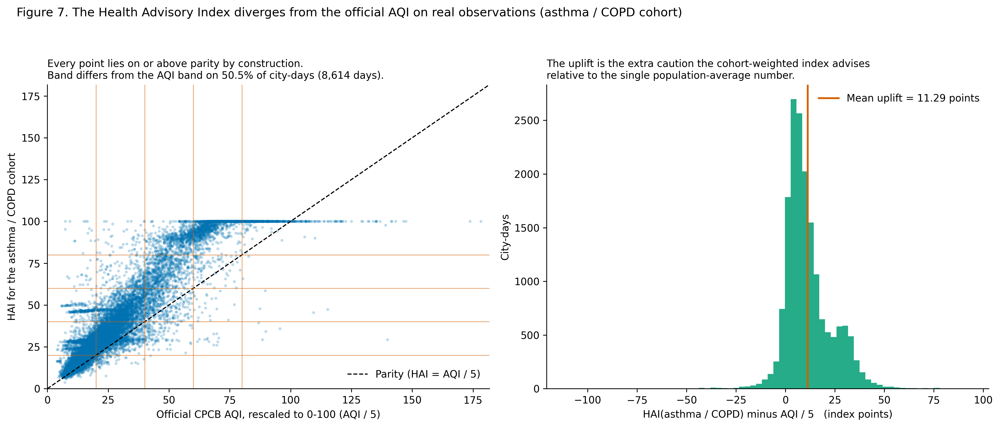

*Figure 3. The index against the official AQI on real observations.*

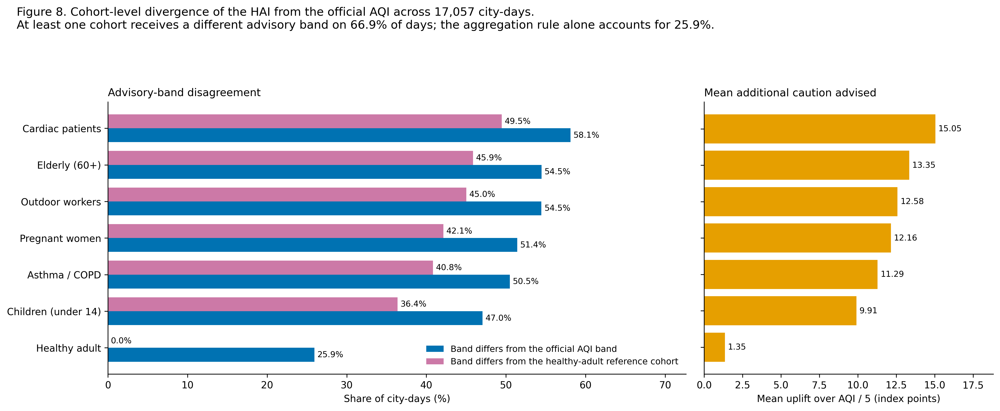

*Figure 4. Divergence by cohort, decomposed.*

In [10]:
show("07_hai_vs_aqi_scatter.png", "Figure 3. The index against the official AQI on real observations.")
show("08_hai_divergence_by_cohort.png", "Figure 4. Divergence by cohort, decomposed.")

## 4. Exploratory analysis

Every figure below has a written interpretation that states the modelling consequence it drives. A chart without one tells a reader nothing.

In [11]:
eda = load("eda_statistics.json")
display(Markdown("### Descriptive statistics"))
display(pd.DataFrame(eda["descriptive"]["per_column"])[[
    "column", "unit", "n", "mean", "std", "median", "p95", "max", "skew", "kurtosis",
]])

### Descriptive statistics

,column,unit,n,mean,std,median,p95,max,skew,kurtosis
0,PM2.5,ug/m3,18395,66.785,63.919,48.07,190.393,949.99,3.622,24.099
1,PM10,ug/m3,18395,121.885,79.621,107.44,276.455,917.08,2.136,7.286
2,NO,ug/m3,18395,14.946,19.580,9.13,52.232,287.14,3.850,20.298
3,NO2,ug/m3,18395,28.794,20.141,23.99,67.640,220.26,1.600,4.126
4,NOx,ppb,18395,28.101,27.461,21.64,80.131,293.10,2.784,11.455
5,NH3,ug/m3,18395,25.993,25.137,20.45,60.869,352.89,4.226,30.197
6,CO,mg/m3,18395,1.172,1.932,0.84,2.560,47.93,8.676,113.020
7,SO2,ug/m3,18395,9.797,9.175,7.69,22.319,187.02,7.678,108.016
8,O3,ug/m3,18395,36.078,20.273,32.53,72.674,257.73,1.596,5.260
9,Benzene,ug/m3,18395,2.565,4.864,1.22,8.356,80.72,6.315,60.677


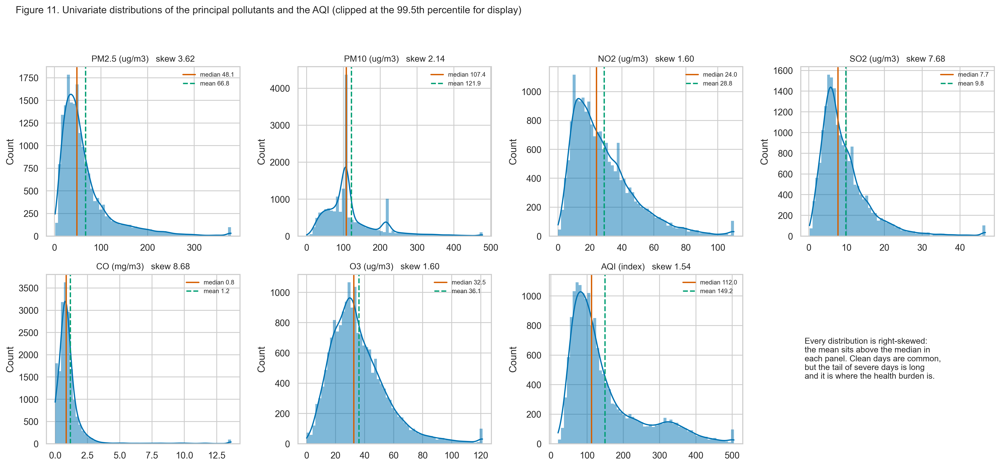

*Figure 5. Univariate distributions.*

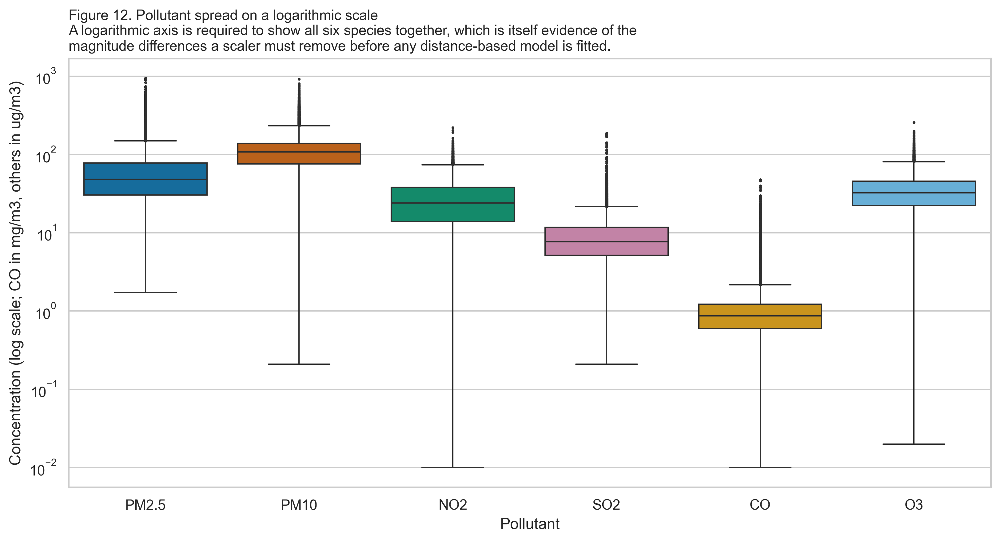

*Figure 6. Pollutant spread on a logarithmic axis.*

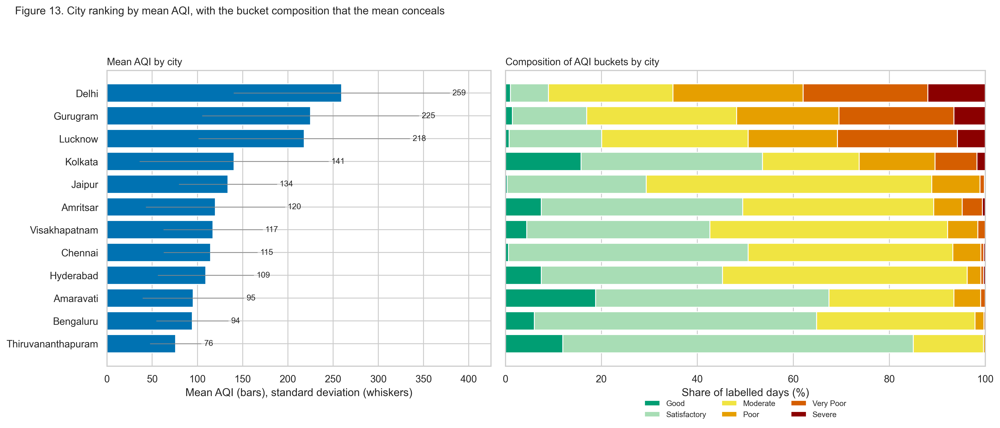

*Figure 7. Cities ranked by mean AQI, with band composition.*

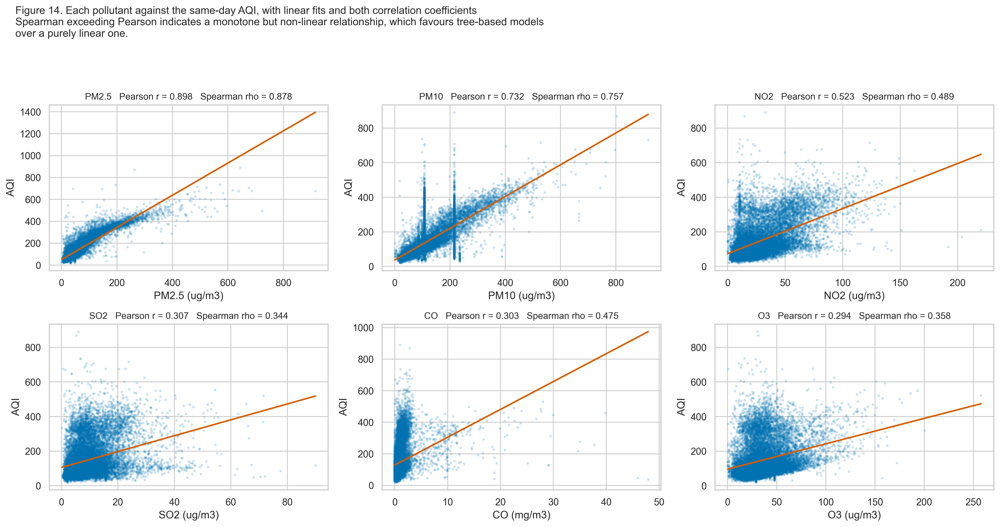

*Figure 8. Each pollutant against the same-day AQI.*

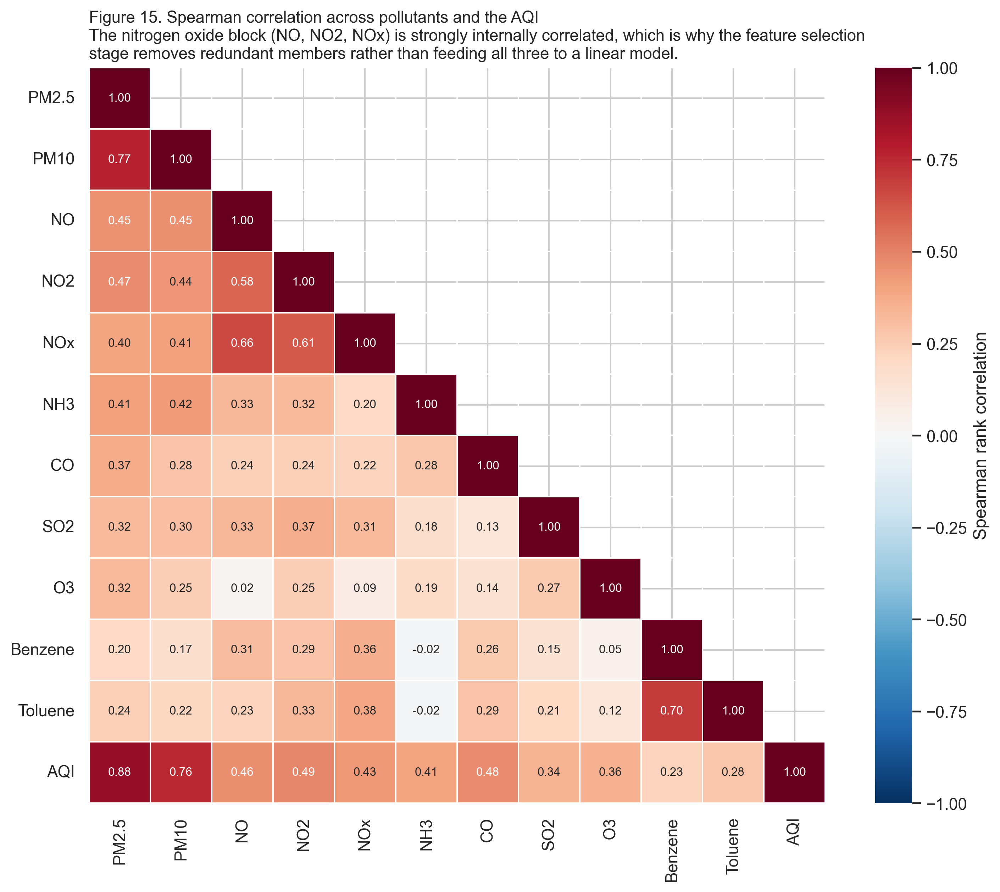

*Figure 9. Spearman correlation across pollutants.*

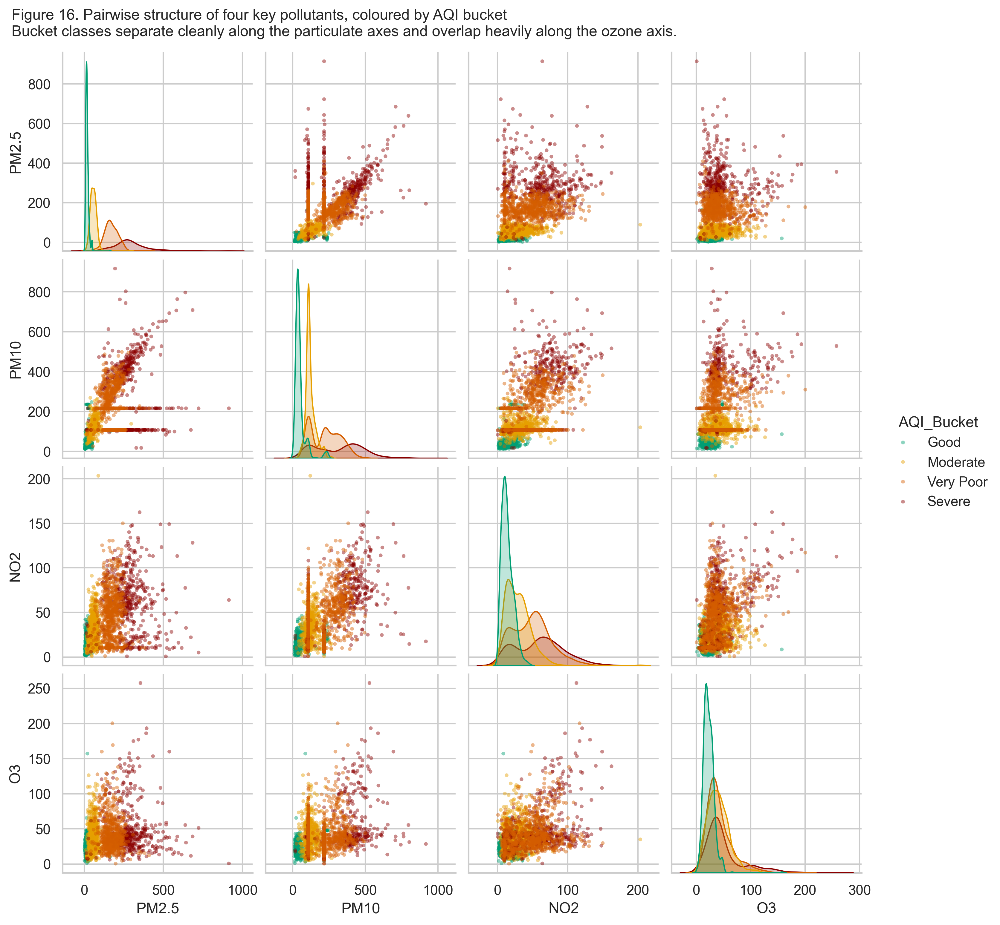

*Figure 10. Pairwise structure, coloured by AQI band.*

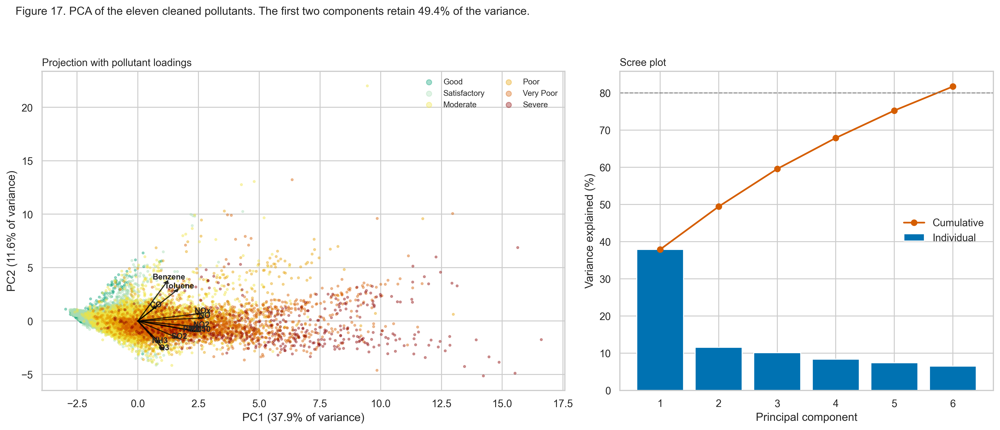

*Figure 11. PCA projection with loadings, and scree plot.*

In [12]:
for name, caption in [
    ("11_univariate_distributions.png", "Figure 5. Univariate distributions."),
    ("12_pollutant_boxplots.png", "Figure 6. Pollutant spread on a logarithmic axis."),
    ("13_city_ranking.png", "Figure 7. Cities ranked by mean AQI, with band composition."),
    ("14_pollutant_vs_aqi.png", "Figure 8. Each pollutant against the same-day AQI."),
    ("15_correlation_heatmap.png", "Figure 9. Spearman correlation across pollutants."),
    ("16_pairplot.png", "Figure 10. Pairwise structure, coloured by AQI band."),
    ("17_pca_projection.png", "Figure 11. PCA projection with loadings, and scree plot."),
]:
    show(name, caption)

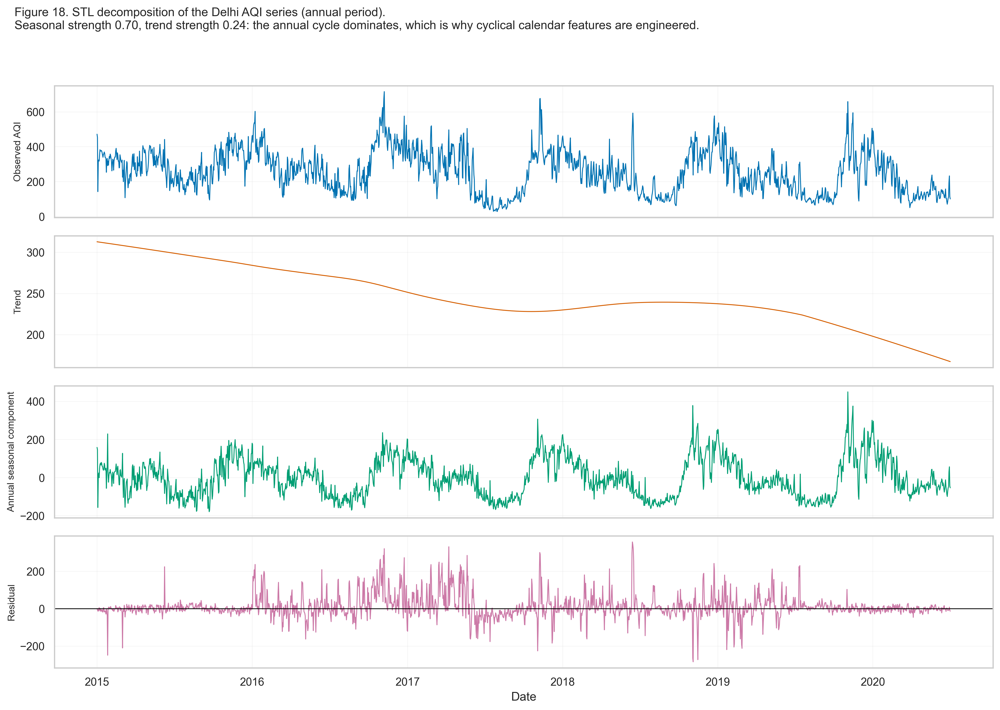

*Figure 12. Seasonal-trend decomposition.*

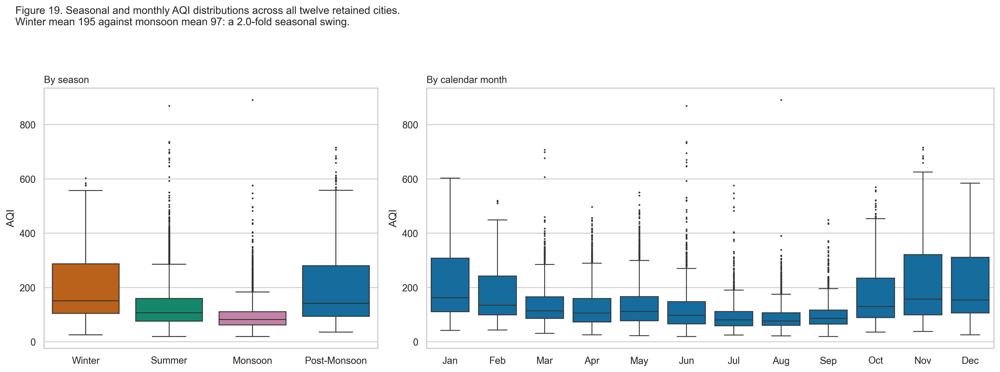

*Figure 13. AQI by season and by month.*

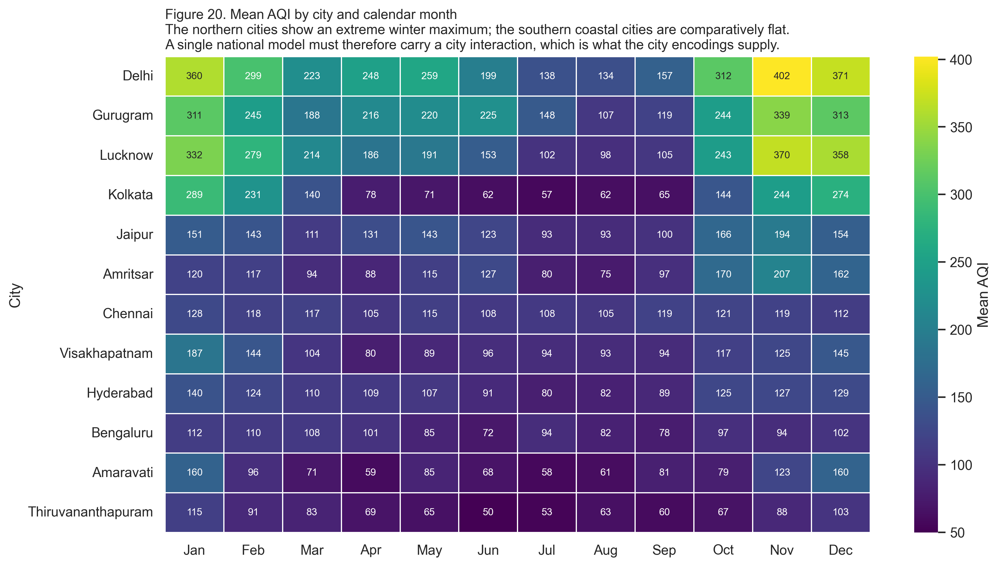

*Figure 14. Mean AQI by city and month.*

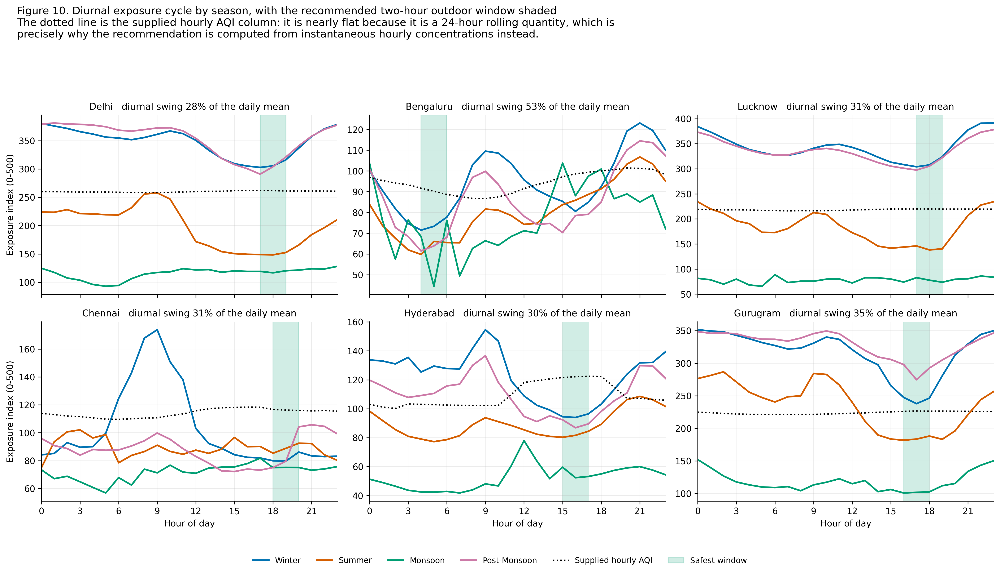

*Figure 15. Diurnal exposure cycle with the safest window shaded.*

In [13]:
for name, caption in [
    ("18_stl_decomposition.png", "Figure 12. Seasonal-trend decomposition."),
    ("19_seasonal_boxplots.png", "Figure 13. AQI by season and by month."),
    ("20_city_month_heatmap.png", "Figure 14. Mean AQI by city and month."),
    ("10_hourly_exposure_climatology.png", "Figure 15. Diurnal exposure cycle with the safest window shaded."),
]:
    show(name, caption)

### The two natural experiments in this record

The span contains two episodes in which emissions changed abruptly for reasons outside the air quality system itself. Both are real signal, both are retained in full, and both are tested for significance rather than described impressionistically.

**Lockdown.** National mean AQI moved from 123.57 to 81.57 (-33.99%), significant at the 5% level in 12 of 12 cities.

**Diwali.** AQI in the festival window is 72.93% above a matched seasonal baseline, significant in 9 of 12 cities, peaking +1 day(s) from Diwali itself.

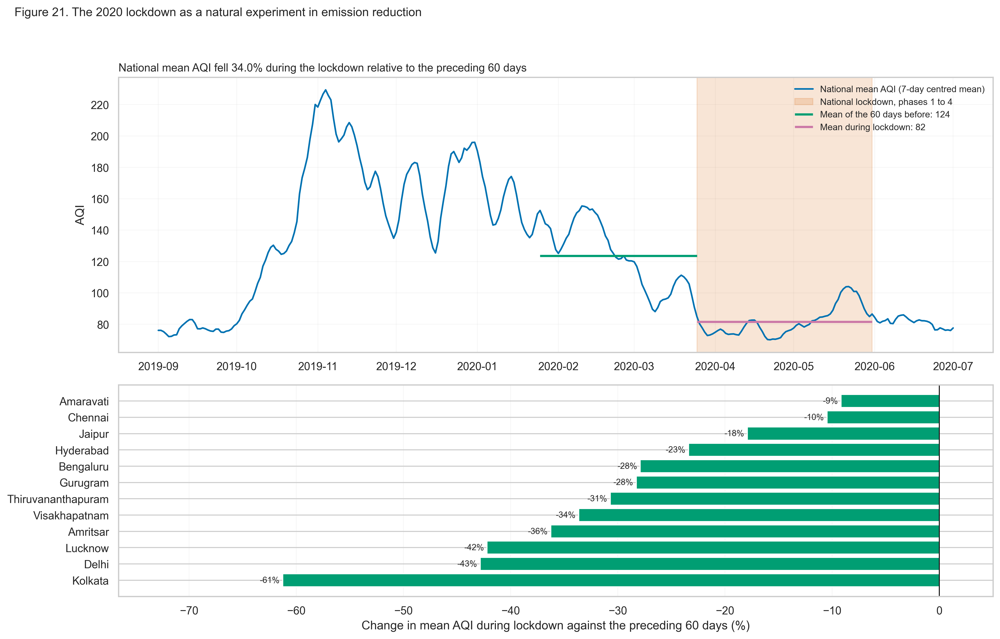

*Figure 16. The 2020 lockdown as a natural experiment.*

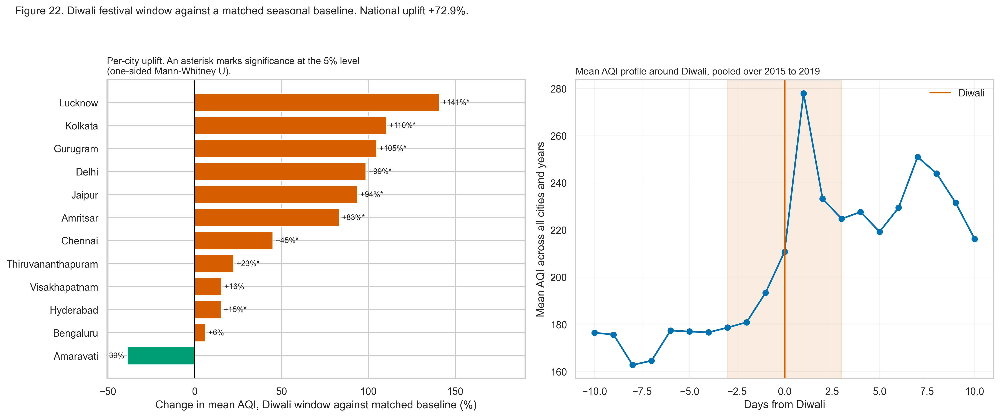

*Figure 17. Diwali against a matched seasonal baseline.*

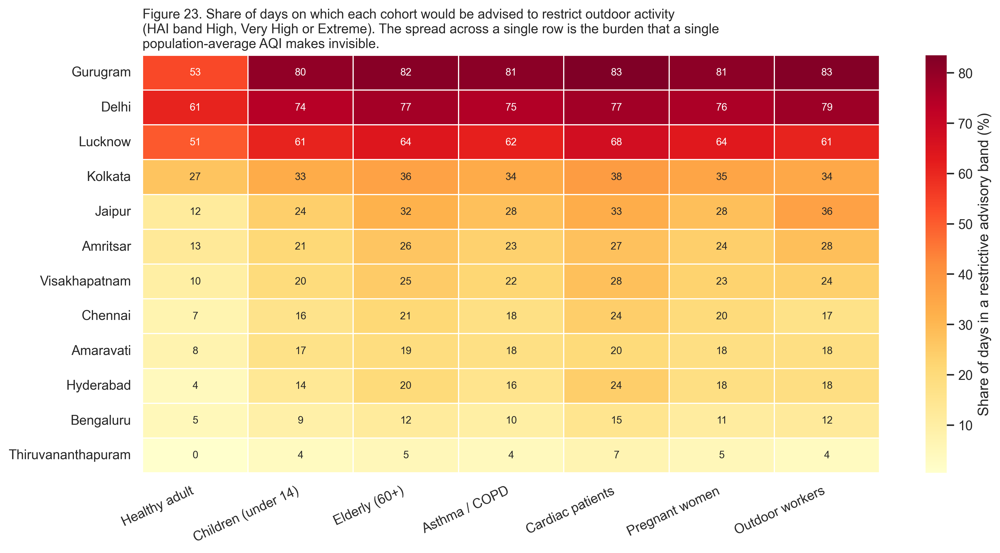

*Figure 18. Advisory burden by cohort and city.*

In [14]:
covid, festival = eda["covid"], eda["festival"]
display(Markdown(
    f"**Lockdown.** National mean AQI moved from {covid['national_mean_before']} "
    f"to {covid['national_mean_during']} ({covid['national_change_pct']}%), "
    f"significant at the 5% level in {covid['n_cities_significant_decline']} of "
    f"{len(covid['per_city'])} cities.\n\n"
    f"**Diwali.** AQI in the festival window is {festival['national_uplift_pct']}% "
    f"above a matched seasonal baseline, significant in "
    f"{festival['n_cities_significant_uplift']} of {len(festival['per_city'])} cities, "
    f"peaking {festival['peak_offset_days']:+d} day(s) from Diwali itself."
))
show("21_covid_interrupted_series.png", "Figure 16. The 2020 lockdown as a natural experiment.")
show("22_diwali_festival_impact.png", "Figure 17. Diwali against a matched seasonal baseline.")
show("23_hai_advisory_burden.png", "Figure 18. Advisory burden by cohort and city.")

## 5. Insights and what they imply for modelling

Each insight cites its figure and states the consequence it drives.

In [15]:
insights = load("eda_insights.json")
for entry in insights["insights"]:
    display(Markdown(
        f"**Insight {entry['id']}** *(see `{entry['figure']}`)*\n\n"
        f"{entry['observation']}\n\n"
        f"> **Consequence for modelling.** {entry['modelling_consequence']}"
    ))

**Insight 1** *(see `11_univariate_distributions.png`)*

Every pollutant distribution is right-skewed. PM2.5 has skewness 3.622 and kurtosis 24.099; the AQI has skewness 1.541. The mean exceeds the median in every panel, and a Shapiro-Wilk test rejects normality for all 12 columns tested.

> **Consequence for modelling.** Error metrics must be reported in pairs. RMSE is dominated by the long upper tail, so MAE is reported alongside it, and the primary regression metric is stated explicitly rather than left implicit. Linear models fitted on untransformed targets will be pulled by the tail, which is one reason a tree ensemble is expected to win.

**Insight 2** *(see `12_pollutant_boxplots.png`)*

The six principal pollutants occupy different orders of magnitude: median CO is 0.84 mg/m3 while median PM10 is 107.44 ug/m3, a ratio of roughly 128 before any unit conversion.

> **Consequence for modelling.** Distance-based and gradient-based learners (KNN, SVM with an RBF kernel, logistic regression) require standardisation, which is applied inside a Pipeline so that the scaler is fitted on training folds only. Tree ensembles are scale-invariant and are fitted without it.

**Insight 3** *(see `13_city_ranking.png`)*

Mean AQI varies more than threefold across the twelve retained cities, and the bucket composition varies far more than the mean suggests: cities with similar means differ substantially in how often they reach the Severe band.

> **Consequence for modelling.** City identity carries real signal, so both a one-hot encoding and a train-only target encoding are constructed and compared. Error is additionally reported per city rather than pooled, because a national average would hide systematic failure in any one city.

**Insight 4** *(see `14_pollutant_vs_aqi.png`)*

PM2.5 is the strongest single correlate of the AQI (Spearman rho = 0.8784), followed by PM10 (rho = 0.7569). Gaseous species are markedly weaker: SO2 reaches only rho = 0.344 and O3 rho = 0.3582.

> **Consequence for modelling.** Tree ensembles will split heavily on the particulate features, which the measured feature importances confirm. It also means a policy lever acting on particulates moves the index far more than one acting on a gaseous species, which is the assumption the policy simulator is built on.

**Insight 5** *(see `15_correlation_heatmap.png`)*

The nitrogen oxide species form a tightly correlated block: PM2.5 with AQI at rho = 0.8784, PM2.5 with PM10 at rho = 0.7684, PM10 with AQI at rho = 0.7569.

> **Consequence for modelling.** Multicollinearity of this magnitude destabilises linear coefficients and inflates their standard errors. A correlation-redundancy filter at |r| > 0.95 is therefore applied before model fitting, and Ridge regression is included specifically to regularise what survives.

...

**Insight 10** *(see `20_city_month_heatmap.png`)*

The seasonal pattern is not national. Northern cities show an extreme winter maximum, while southern coastal cities are comparatively flat across the year.

> **Consequence for modelling.** The city-by-season interaction is real, so a purely additive model is mis-specified. Tree ensembles capture the interaction without it being stated, which is a further reason to expect them to outperform the linear baseline.

**Insight 11** *(see `21_covid_interrupted_series.png`)*

National mean AQI changed by -33.99% during the lockdown against the preceding 60 days, and the decline is significant at the 5% level in 12 of 12 cities by a one-sided Mann-Whitney U test.

> **Consequence for modelling.** 2020 is a genuine regime change, not noise. It is handled with an explicit lockdown flag rather than deletion, and test-set error is additionally broken out for the lockdown period so that its contribution is visible. It also provides the empirical anchor for the policy simulator: a large, abrupt emission reduction did move the index, by a measured amount.

**Insight 12** *(see `22_diwali_festival_impact.png`)*

AQI in the Diwali window is 72.93% above a matched baseline drawn from the same season three to five weeks earlier, and the uplift is significant at the 5% level in 9 of 12 cities. The pooled profile peaks 1 day(s) from Diwali itself.

> **Consequence for modelling.** These spikes are real signal and must not be removed as outliers. The outlier policy explicitly exempts documented event windows from the statistical spike rule, and a festival flag is supplied as a feature so the model can anticipate rather than merely absorb them.

**Insight 13** *(see `23_hai_advisory_burden.png`)*

Under the HAI the share of days requiring a restrictive advisory differs sharply by cohort: Healthy adult 23.03%, Children (under 14) 33.42%, Elderly (60+) 37.42%, Asthma / COPD 34.81%, Cardiac patients 39.7%, Pregnant women 36.1%, Outdoor workers 36.78%.

> **Consequence for modelling.** A single population-average index under-serves the most exposed groups by a measurable margin. This is the quantitative justification for the cohort-resolved advisory that the application delivers, and it is the outcome the policy simulator reports against.

**Insight 14** *(see `10_hourly_exposure_climatology.png`)*

Within-day exposure varies by roughly 40% of the daily mean once it is computed from instantaneous hourly concentrations, whereas the supplied hourly AQI column varies by only about 8% because it is a 24-hour rolling quantity.

> **Consequence for modelling.** A daily index cannot support a within-day recommendation. The safest outdoor window is therefore computed from hourly concentrations and is presented as a relative exposure indicator, explicitly distinguished from the official AQI.

## 6. Phase 2 outcome

* Cleaning decisions made by measurement, not preference.
* Genuine pollution episodes retained; artefacts removed on a stated physical rule.
* Feature matrix built with every leakage control in place.
* Health Advisory Index built, its properties proved, its divergence from the official AQI measured.
* Exploratory analysis complete, every figure interpreted.

Phase 3 trains, compares, tunes, explains and ships.